# 04 · Price Prediction Model

Predicts a property's listing price from its size, location and attributes.

### Fixes compared with the original modelling code
| Issue in original | Why it matters | Fix |
|---|---|---|
| `Price per sqft` used as an input feature | It is calculated **from** price, so the model was effectively given the answer (target leakage). This inflated test R² to 0.98. | Removed from the features |
| Raw price as target | Heavily skewed, so a few crore-rupee homes dominate the error | Model `log(price)` and convert predictions back to ₹ |
| One random train/test split | A single split can be lucky or unlucky | 5-fold cross-validation plus a held-out test set |
| Raw area with a log target | Linear models extrapolate exponentially for very large homes, so one fold scored R² < 0 | Use `log(area)` (log-log model) |
| Swapped latitude/longitude, typo prices | Wrong geography and absurd prices | Fixed in notebook 02 |
| `normalize=` and `criterion='mse'` arguments | Removed in recent scikit-learn, so the code crashes | Replaced with current equivalents |

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

ROOT = Path('..')
IMG_DIR = ROOT / 'images'
IMG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
import joblib

RANDOM_STATE = 42

## 1. Load data and choose features

In [2]:
df = pd.read_csv(ROOT / 'data/processed/magicbricks_cleaned.csv')
df['Log Area'] = np.log(df['Area(sqft)'])   # price grows multiplicatively with size

numeric = ['Log Area', 'Bedrooms', 'Bathroom', 'Parking', 'Latitude', 'Longitude']
categorical = ['City', 'Tier', 'State/Territory', 'Property Type', 'Transaction', 'Furnishing', 'Status']
features = numeric + categorical

X = df[features]
y = df['Price']
print('Rows:', len(df), '| Features:', len(features))
assert 'Price per sqft' not in features  # guard against target leakage

Rows: 2004 | Features: 13


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (1603, 13) | Test: (401, 13)


## 2. Preprocessing pipeline
* **Numeric columns:** fill missing coordinates with the median, then standardise.
* **Categorical columns:** one-hot encode, ignoring categories not seen during training.

Everything is wrapped in a scikit-learn `Pipeline`, so the exact same transformations are applied at prediction time.

In [4]:
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
])

def make_model(regressor):
    # Fit on log(price); predictions are converted back to rupees automatically
    return TransformedTargetRegressor(
        regressor=Pipeline([('prep', preprocess), ('model', regressor)]),
        func=np.log, inverse_func=np.exp)

candidates = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'K-Nearest Neighbours': KNeighborsRegressor(n_neighbors=7, weights='distance'),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=4,
                                                   subsample=0.8, random_state=RANDOM_STATE),
}

## 3. Compare models with 5-fold cross-validation

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, reg in candidates.items():
    scores = cross_validate(make_model(reg), X_train, y_train, cv=cv,
                            scoring={'r2': 'r2', 'mape': 'neg_mean_absolute_percentage_error'})
    rows.append({'Model': name,
                 'CV R²': scores['test_r2'].mean(),
                 'CV R² std': scores['test_r2'].std(),
                 'CV MAPE %': -scores['test_mape'].mean() * 100})
cv_results = pd.DataFrame(rows).set_index('Model').sort_values('CV MAPE %')
cv_results.round(3)

,CV R²,CV R² std,CV MAPE %
Model,,,
Gradient Boosting,0.761,0.066,22.770
Random Forest,0.713,0.105,25.360
Ridge Regression,0.775,0.036,26.456
Linear Regression,0.777,0.037,26.518
K-Nearest Neighbours,0.608,0.086,30.087


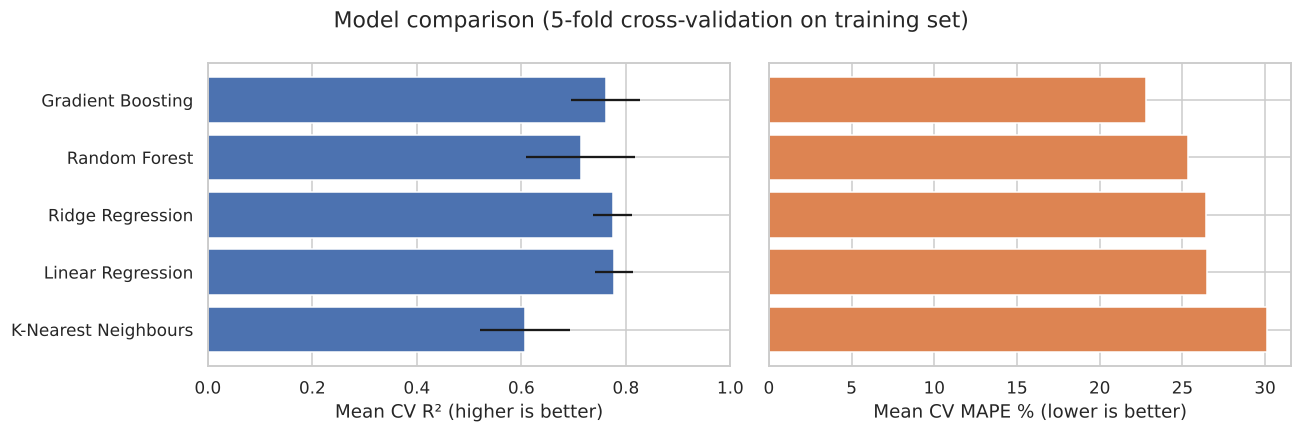

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.barh(cv_results.index, cv_results['CV R²'], xerr=cv_results['CV R² std'], color='#4C72B0')
ax1.invert_yaxis(); ax1.set_xlim(0, 1); ax1.set_xlabel('Mean CV R² (higher is better)')
ax2.barh(cv_results.index, cv_results['CV MAPE %'], color='#DD8452')
ax2.invert_yaxis(); ax2.set_xlabel('Mean CV MAPE % (lower is better)'); ax2.set_yticklabels([])
fig.suptitle('Model comparison (5-fold cross-validation on training set)')
save(fig, 're_11_model_comparison')

The models are ranked by **cross-validated MAPE** (mean absolute percentage error). Prices range from ₹9 Lakh to ₹24 Cr, and raw-scale R² is dominated by the few most expensive homes. MAPE weights a ₹30 Lakh flat and a ₹3 Cr villa equally, which is what a buyer cares about: *how far off is the estimate for my home?*

## 4. Evaluate the best model on the held-out test set

In [7]:
best_name = cv_results.index[0]
best_model = make_model(candidates[best_name]).fit(X_train, y_train)
pred = best_model.predict(X_test)

test_metrics = {
    'R²': r2_score(y_test, pred),
    'R² on log scale': r2_score(np.log(y_test), np.log(pred)),
    'MAE (₹ Lakh)': mean_absolute_error(y_test, pred) / 1e5,
    'Median abs. error (₹ Lakh)': np.median(np.abs(y_test - pred)) / 1e5,
    'MAPE %': mean_absolute_percentage_error(y_test, pred) * 100,
}
print('Best model:', best_name)
pd.Series(test_metrics).round(3)

Best model: Gradient Boosting


R²                             0.808
R² on log scale                0.826
MAE (₹ Lakh)                  25.492
Median abs. error (₹ Lakh)    13.759
MAPE %                        25.127
dtype: float64

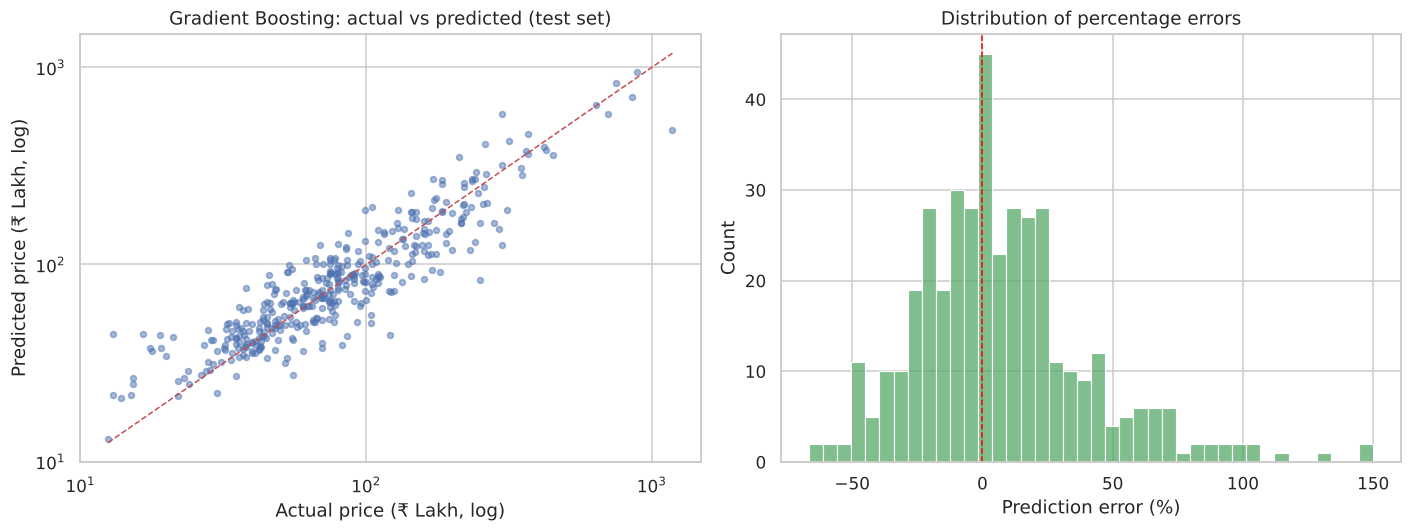

Share of test predictions within ±20% of actual price: 53%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test / 1e5, pred / 1e5, alpha=0.5, s=15)
lim = [y_test.min() / 1e5, y_test.max() / 1e5]
axes[0].plot(lim, lim, 'r--', lw=1); axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('Actual price (₹ Lakh, log)'); axes[0].set_ylabel('Predicted price (₹ Lakh, log)')
axes[0].set_title(f'{best_name}: actual vs predicted (test set)')
pct_err = (pred - y_test) / y_test * 100
sns.histplot(pct_err.clip(-100, 150), bins=40, ax=axes[1], color='#55A868')
axes[1].axvline(0, color='red', ls='--', lw=1)
axes[1].set_xlabel('Prediction error (%)'); axes[1].set_title('Distribution of percentage errors')
save(fig, 're_12_actual_vs_predicted')
print(f'Share of test predictions within ±20% of actual price: {(pct_err.abs() <= 20).mean():.0%}')

## 5. What drives the prediction?

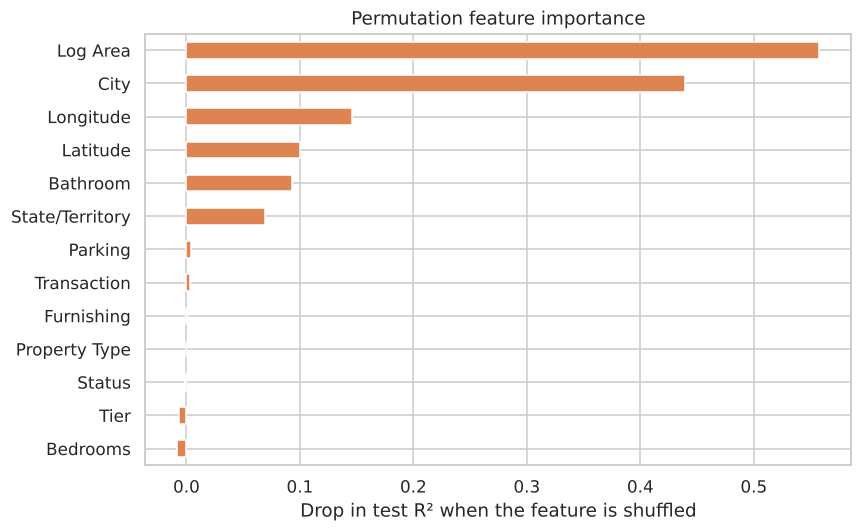

Log Area           0.558
City               0.439
Longitude          0.146
Latitude           0.100
Bathroom           0.093
State/Territory    0.069
Parking            0.004
Transaction        0.003
Furnishing         0.000
Property Type     -0.000
Status            -0.001
Tier              -0.006
Bedrooms          -0.008
dtype: float64

In [9]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                              scoring='r2', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=features).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
importance.plot(kind='barh', ax=ax, color='#DD8452')
ax.set_xlabel('Drop in test R² when the feature is shuffled'); ax.set_title('Permutation feature importance')
save(fig, 're_13_feature_importance')
importance.sort_values(ascending=False).round(3)

Permutation importance measures how much accuracy drops when one input column is randomly shuffled. Unlike tree-based impurity importance, it works on the original columns (before one-hot encoding), so the results are easy to read.

## 6. Leakage check — what the original approach would have reported

In [10]:
leaky = make_model(candidates[best_name])
leaky_num = numeric + ['Price per sqft']
leaky.regressor.set_params(prep=ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), leaky_num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical)]))
Xl_train, Xl_test = train_test_split(df[leaky_num + categorical], test_size=0.2, random_state=RANDOM_STATE)
leaky.fit(Xl_train, y_train)
leaky_pred = leaky.predict(Xl_test)
print(pd.DataFrame({
    'R²': [r2_score(y_test, leaky_pred), test_metrics['R²']],
    'R² (log scale)': [r2_score(np.log(y_test), np.log(leaky_pred)), test_metrics['R² on log scale']],
    'MAPE %': [mean_absolute_percentage_error(y_test, leaky_pred) * 100, test_metrics['MAPE %']],
}, index=["WITH leaked 'Price per sqft' (not usable)", 'Without leakage (honest)']).round(3))

                                              R²  R² (log scale)  MAPE %
WITH leaked 'Price per sqft' (not usable)  0.994           0.998   2.556
Without leakage (honest)                   0.808           0.826  25.127


`Price per sqft` is unknown for a new property; it's exactly what we're trying to estimate. A model that depends on it can't be used in practice, so the honest score is the one reported above.

## 7. Train on all data, save and use the model

In [11]:
final_model = make_model(candidates[best_name]).fit(X, y)
(ROOT / 'models').mkdir(exist_ok=True)
joblib.dump(final_model, ROOT / 'models/price_model.joblib')
print('Saved model to models/price_model.joblib')

Saved model to models/price_model.joblib


In [12]:
def predict_price(area_sqft, bedrooms, bathrooms, city, parking=1, property_type='Flat',
                  transaction='New Property', furnishing='Unfurnished', status='Ready to Move'):
    """Predict the listing price (₹) for one property. Coordinates default to the city's median."""
    city_rows = df[df['City'] == city]
    if city_rows.empty:
        raise ValueError(f'Unknown city: {city}')
    row = pd.DataFrame([{
        'Log Area': np.log(area_sqft), 'Bedrooms': bedrooms, 'Bathroom': bathrooms, 'Parking': parking,
        'Latitude': city_rows['Latitude'].median(), 'Longitude': city_rows['Longitude'].median(),
        'City': city, 'Tier': city_rows['Tier'].iloc[0], 'State/Territory': city_rows['State/Territory'].iloc[0],
        'Property Type': property_type, 'Transaction': transaction, 'Furnishing': furnishing, 'Status': status,
    }])
    return float(final_model.predict(row[features])[0])

examples = [
    dict(area_sqft=1000, bedrooms=2, bathrooms=2, city='Pune'),
    dict(area_sqft=1000, bedrooms=2, bathrooms=2, city='Mumbai'),
    dict(area_sqft=1500, bedrooms=3, bathrooms=3, city='Bangalore', furnishing='Semi-Furnished'),
    dict(area_sqft=1200, bedrooms=2, bathrooms=2, city='Ahmedabad', transaction='Resale'),
]
pd.DataFrame([{**e, 'Predicted price (₹ Lakh)': round(predict_price(**e) / 1e5, 1)} for e in examples])

,area_sqft,bedrooms,bathrooms,city,Predicted price (₹ Lakh),furnishing,transaction
0,1000,2,2,Pune,75.1,NaN,NaN
1,1000,2,2,Mumbai,215.2,NaN,NaN
2,1500,3,3,Bangalore,110.3,Semi-Furnished,NaN
3,1200,2,2,Ahmedabad,59.3,NaN,Resale


**Sanity check:** the same 1,000 sqft 2 BHK is predicted at about ₹75 Lakh in Pune and ₹215 Lakh in Mumbai. That's roughly ₹7,500 vs ₹21,500 per sqft, in line with each city's median price per sqft from the EDA.

## Summary
| | Value |
|---|---|
| Final model | Gradient Boosting on log(price) |
| Cross-validated MAPE | ~23% |
| Test R² (₹ scale / log scale) | 0.81 / 0.83 |
| Test MAPE | ~25%; about half of predictions within ±20% |

* **Size and location dominate.** `log(area)` and `City`, followed by the exact coordinates and the number of bathrooms, carry nearly all the predictive power. Bedrooms add almost nothing once area and bathrooms are known, because the three are highly correlated.
* **Linear/Ridge regression score a similar R²** but a higher percentage error. Gradient Boosting captures the non-linear city-by-size effects better.
* **Leakage matters.** Including `Price per sqft` would have reported a fake R² of 0.99. The honest model is less impressive on paper, but it can price an unseen property.
* **Limitations:** about 2,000 listings across 59 cities, so smaller cities have few examples. These are asking prices, not sale prices, and amenities and floor level aren't modelled yet.